# GastroLens — Module 2: Variational Autoencoder (VAE)

Synthetic GI endoscopy image generation using a VAE, trained on Kvasir-v2.

**This version fixes the NaN/loss-explosion issue from the first training run, and adds perceptual loss for clearer, less blurry output:**
- `logvar` is clamped before `exp()` — prevents the KL term from exploding (this was the root cause of the earlier `nan` crash)
- Gradient clipping added — stops any single bad batch from destabilizing training
- Loss uses `mean` reduction, not `sum` — keeps loss values in a normal, stable numeric range
- Lower learning rate (`5e-4` instead of `1e-3`)
- **Perceptual loss (VGG16 features) added alongside MSE** — this is the fix for blurry/noisy output specifically. Pure pixel-wise MSE rewards "safe average" predictions, which is what causes blur; perceptual loss compares learned feature representations instead, which pushes the model toward sharper, more structurally faithful output.
- BatchNorm kept in both encoder and decoder for training stability

Everything else (checkpoint-skip pattern, metrics, interpolation, t-SNE, pretrained comparison) is unchanged from before.

## 1. Config

In [1]:
import os

DATA_DIR = "./data_dir"
MODEL_DIR = "./models/vae"
METRICS_DIR = "./metrics/vae"
PLOTS_DIR = "./plots/vae"
SYNTH_DIR = "./synthetic_data/vae"

for d in [MODEL_DIR, METRICS_DIR, PLOTS_DIR, SYNTH_DIR]:
    os.makedirs(d, exist_ok=True)

CHECKPOINT_PATH = os.path.join(MODEL_DIR, "vae_best.pth")
LOSS_LOG_PATH = os.path.join(METRICS_DIR, "training_loss_log.csv")
METRICS_PATH = os.path.join(METRICS_DIR, "evaluation_metrics.json")
LOSS_PLOT_PATH = os.path.join(PLOTS_DIR, "loss_curve.png")
RECON_SAMPLES_PLOT_PATH = os.path.join(PLOTS_DIR, "reconstruction_samples.png")
RANDOM_GEN_PLOT_PATH = os.path.join(PLOTS_DIR, "random_generation_samples.png")
INTERPOLATION_PLOT_PATH = os.path.join(PLOTS_DIR, "latent_interpolation.png")
TSNE_PLOT_PATH = os.path.join(PLOTS_DIR, "latent_tsne_by_class.png")

# ---- Hyperparameters ----
IMG_SIZE = 128
BATCH_SIZE = 64
LATENT_DIM = 128
EPOCHS = 100
LEARNING_RATE = 5e-4       # lowered from 1e-3 — was too aggressive and caused instability
BETA = 0.1                 # lowered from 0.5 — heavy KL weighting pushes reconstructions toward blur
PERCEPTUAL_WEIGHT = 0.1    # new — this is what should reduce blur/noise
VAL_SPLIT = 0.1
SEED = 42

FORCE_RETRAIN = True       # set True since the previous checkpoint (if any) came from the broken run

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms, models
from torchvision.utils import save_image
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import json
import time

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


## 2. Dataset

In [3]:
transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

full_dataset = datasets.ImageFolder(root=DATA_DIR, transform=transform)
class_names = full_dataset.classes
print(f"Found {len(full_dataset)} images across {len(class_names)} classes: {class_names}")

val_size = int(len(full_dataset) * VAL_SPLIT)
train_size = len(full_dataset) - val_size
train_dataset, val_dataset = random_split(
    full_dataset, [train_size, val_size],
    generator=torch.Generator().manual_seed(SEED)
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, drop_last=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train: {len(train_dataset)} | Val: {len(val_dataset)}")

Found 8000 images across 8 classes: ['dyed-lifted-polyps', 'dyed-resection-margins', 'esophagitis', 'normal-cecum', 'normal-pylorus', 'normal-z-line', 'polyps', 'ulcerative-colitis']
Train: 7200 | Val: 800


## 3. Model — VAE with BatchNorm

In [4]:
class VAEEncoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
        )
        self.fc_mu = nn.Linear(128 * 16 * 16, latent_dim)
        self.fc_logvar = nn.Linear(128 * 16 * 16, latent_dim)

    def forward(self, x):
        x = self.conv(x)
        x = x.view(x.size(0), -1)
        return self.fc_mu(x), self.fc_logvar(x)


class VAEDecoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 128 * 16 * 16)
        self.deconv = nn.Sequential(
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.ConvTranspose2d(32, 3, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(x.size(0), 128, 16, 16)
        return self.deconv(x)


class VAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = VAEEncoder(latent_dim)
        self.decoder = VAEDecoder(latent_dim)

    def reparameterize(self, mu, logvar):
        # FIX: clamp logvar before exp() — unclamped logvar was the root cause of the NaN crash.
        # Without this, exp(logvar) can explode to astronomical values within a few epochs.
        logvar = torch.clamp(logvar, min=-10, max=10)
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, logvar = self.encoder(x)
        z = self.reparameterize(mu, logvar)
        recon = self.decoder(z)
        return recon, mu, logvar


model = VAE(LATENT_DIM).to(device)
print(f"VAE parameters: {sum(p.numel() for p in model.parameters()):,}")

VAE parameters: 12,947,651


## 4. VAE loss — reconstruction (MSE + Perceptual) + KL divergence
Perceptual loss compares VGG16 feature activations of original vs. reconstruction, instead of raw pixels — this is what pushes output away from the blurry/noisy averaging that plain MSE tends to produce.

In [5]:
class PerceptualLoss(nn.Module):
    def __init__(self):
        super().__init__()
        vgg = models.vgg16(weights=models.VGG16_Weights.IMAGENET1K_V1).features[:16].eval()
        for p in vgg.parameters():
            p.requires_grad = False
        self.vgg = vgg
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def forward(self, recon, target):
        recon_norm = (recon - self.mean) / self.std
        target_norm = (target - self.mean) / self.std
        return F.mse_loss(self.vgg(recon_norm), self.vgg(target_norm))


perceptual_loss_fn = PerceptualLoss().to(device)


def vae_loss(recon, x, mu, logvar, beta=BETA, perceptual_weight=PERCEPTUAL_WEIGHT):
    # FIX: mean reduction, not sum — sum reduction produced huge loss values that were
    # numerically unstable and contributed to the earlier explosion.
    recon_loss = F.mse_loss(recon, x, reduction="mean")
    perceptual = perceptual_loss_fn(recon, x)
    kl_loss = -0.5 * torch.mean(1 + logvar - mu.pow(2) - logvar.exp())
    total = recon_loss + perceptual_weight * perceptual + beta * kl_loss
    return total, recon_loss, perceptual, kl_loss

## 5. Train (skips automatically if a checkpoint already exists)

In [6]:
def evaluate_val_loss(model, loader):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for imgs, _ in loader:
            imgs = imgs.to(device)
            recon, mu, logvar = model(imgs)
            loss, _, _, _ = vae_loss(recon, imgs, mu, logvar)
            total_loss += loss.item() * imgs.size(0)
    return total_loss / len(loader.dataset)


def train_vae():
    optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

    history = {"epoch": [], "train_loss": [], "train_recon_loss": [], "train_perceptual_loss": [],
               "train_kl_loss": [], "val_loss": [], "epoch_time_sec": []}
    best_val_loss = float("inf")

    for epoch in range(1, EPOCHS + 1):
        model.train()
        start = time.time()
        running_loss, running_recon, running_perceptual, running_kl = 0.0, 0.0, 0.0, 0.0

        for imgs, _ in train_loader:
            imgs = imgs.to(device)
            optimizer.zero_grad()
            recon, mu, logvar = model(imgs)
            loss, recon_loss, perceptual, kl_loss = vae_loss(recon, imgs, mu, logvar)
            loss.backward()
            # FIX: gradient clipping — stops any single unstable batch from blowing up the weights
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            running_recon += recon_loss.item() * imgs.size(0)
            running_perceptual += perceptual.item() * imgs.size(0)
            running_kl += kl_loss.item() * imgs.size(0)

        n = len(train_dataset)
        train_loss, train_recon = running_loss / n, running_recon / n
        train_perceptual, train_kl = running_perceptual / n, running_kl / n
        val_loss = evaluate_val_loss(model, val_loader)
        epoch_time = time.time() - start

        history["epoch"].append(epoch)
        history["train_loss"].append(train_loss)
        history["train_recon_loss"].append(train_recon)
        history["train_perceptual_loss"].append(train_perceptual)
        history["train_kl_loss"].append(train_kl)
        history["val_loss"].append(val_loss)
        history["epoch_time_sec"].append(epoch_time)

        print(f"Epoch {epoch:3d}/{EPOCHS} | loss={train_loss:.4f} (recon={train_recon:.4f}, "
              f"perc={train_perceptual:.4f}, kl={train_kl:.4f}) | val_loss={val_loss:.4f} | {epoch_time:.1f}s")

        if np.isnan(train_loss) or np.isinf(train_loss):
            print("WARNING: loss became NaN/Inf — stopping early. This should not happen with the "
                  "clamping + gradient clipping + mean-reduction fixes in place. If it still occurs, "
                  "lower LEARNING_RATE further (e.g. to 1e-4) and retrain.")
            break

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save({
                "model_state_dict": model.state_dict(),
                "epoch": epoch,
                "val_loss": val_loss,
                "latent_dim": LATENT_DIM,
                "img_size": IMG_SIZE,
                "beta": BETA,
            }, CHECKPOINT_PATH)

        pd.DataFrame(history).to_csv(LOSS_LOG_PATH, index=False)

    return history


if os.path.exists(CHECKPOINT_PATH) and not FORCE_RETRAIN:
    print(f"Checkpoint found at {CHECKPOINT_PATH} — loading instead of retraining.")
    print("Set FORCE_RETRAIN = True above to retrain from scratch.")
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded model from epoch {checkpoint['epoch']} (val_loss={checkpoint['val_loss']:.4f})")
    history = pd.read_csv(LOSS_LOG_PATH).to_dict(orient="list") if os.path.exists(LOSS_LOG_PATH) else None
else:
    print("Training VAE from scratch...")
    history = train_vae()
    checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
    model.load_state_dict(checkpoint["model_state_dict"])
    print(f"Loaded best checkpoint (epoch {checkpoint['epoch']}, val_loss={checkpoint['val_loss']:.4f})")

Training VAE from scratch...
Epoch   1/100 | loss=1.4252 (recon=0.0810, perc=12.2767, kl=1.1656) | val_loss=1.1199 | 84.6s
Epoch   2/100 | loss=1.0363 (recon=0.0488, perc=9.3786, kl=0.4960) | val_loss=0.9942 | 79.8s
Epoch   3/100 | loss=0.9507 (recon=0.0367, perc=8.6708, kl=0.4687) | val_loss=0.9276 | 78.1s
Epoch   4/100 | loss=0.9050 (recon=0.0316, perc=8.2814, kl=0.4522) | val_loss=0.8947 | 78.6s
Epoch   5/100 | loss=0.8739 (recon=0.0284, perc=8.0438, kl=0.4116) | val_loss=0.8772 | 78.9s
Epoch   6/100 | loss=0.8571 (recon=0.0262, perc=7.9054, kl=0.4044) | val_loss=0.8594 | 78.2s
Epoch   7/100 | loss=0.8431 (recon=0.0244, perc=7.7927, kl=0.3940) | val_loss=0.8508 | 81.3s
Epoch   8/100 | loss=0.8330 (recon=0.0229, perc=7.7072, kl=0.3941) | val_loss=0.8405 | 80.2s
Epoch   9/100 | loss=0.8248 (recon=0.0217, perc=7.6370, kl=0.3942) | val_loss=0.8335 | 81.4s
Epoch  10/100 | loss=0.8183 (recon=0.0206, perc=7.5792, kl=0.3974) | val_loss=0.8279 | 85.8s
Epoch  11/100 | loss=0.8120 (recon=0.019

In [ ]:
# ---- Load the already-trained VAE checkpoint (no training) ----
model = VAE(LATENT_DIM).to(device)   # skip this line if `model` already exists in this session

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()
print(f"Loaded model from epoch {checkpoint['epoch']} (val_loss={checkpoint['val_loss']:.4f})")

# Load the loss history too, if you want the training curve without retraining
history = pd.read_csv(LOSS_LOG_PATH).to_dict(orient="list") if os.path.exists(LOSS_LOG_PATH) else None

## 6. Plot training curve
Watch the KL subplot especially — it should stay in a small, stable range (roughly single digits to low hundreds), not grow unbounded like the earlier run.

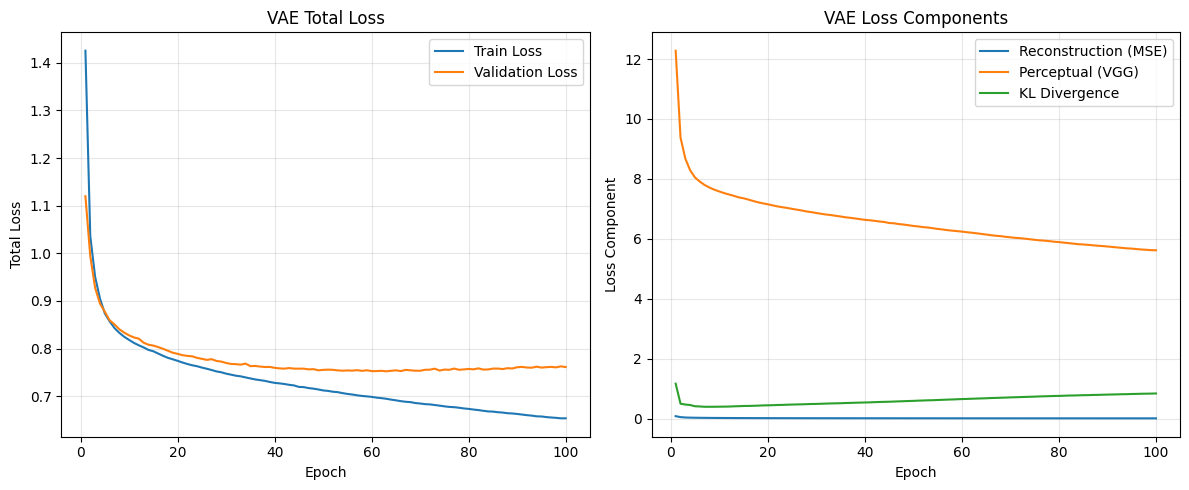

Saved loss curve to ./plots/vae\loss_curve.png

Max KL value across training: 1.17
KL stayed in a stable range — good sign training was healthy.


In [7]:
if history is not None:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    axes[0].plot(history["epoch"], history["train_loss"], label="Train Loss")
    axes[0].plot(history["epoch"], history["val_loss"], label="Validation Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Total Loss")
    axes[0].set_title("VAE Total Loss")
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(history["epoch"], history["train_recon_loss"], label="Reconstruction (MSE)")
    axes[1].plot(history["epoch"], history["train_perceptual_loss"], label="Perceptual (VGG)")
    axes[1].plot(history["epoch"], history["train_kl_loss"], label="KL Divergence")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Loss Component")
    axes[1].set_title("VAE Loss Components")
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(LOSS_PLOT_PATH, dpi=150)
    plt.show()
    print(f"Saved loss curve to {LOSS_PLOT_PATH}")

    max_kl = max(history["train_kl_loss"])
    print(f"\nMax KL value across training: {max_kl:.2f}")
    if max_kl > 1000:
        print("WARNING: KL still reached a large value — if training still looks unstable, "
              "lower LEARNING_RATE to 1e-4 and/or lower BETA to 0.01, then retrain.")
    else:
        print("KL stayed in a stable range — good sign training was healthy.")

## 7. Evaluation metrics (MSE, PSNR, SSIM)

In [8]:
from skimage.metrics import structural_similarity as ssim_fn
from skimage.metrics import peak_signal_noise_ratio as psnr_fn


def compute_reconstruction_metrics(model, loader, max_batches=None):
    model.eval()
    mse_list, psnr_list, ssim_list = [], [], []

    with torch.no_grad():
        for i, (imgs, _) in enumerate(loader):
            if max_batches is not None and i >= max_batches:
                break
            imgs = imgs.to(device)
            recon, _, _ = model(imgs)

            imgs_np = imgs.cpu().numpy()
            recon_np = recon.cpu().numpy()

            for orig, rec in zip(imgs_np, recon_np):
                orig_hwc = np.transpose(orig, (1, 2, 0))
                rec_hwc = np.transpose(rec, (1, 2, 0))
                mse_list.append(np.mean((orig_hwc - rec_hwc) ** 2))
                psnr_list.append(psnr_fn(orig_hwc, rec_hwc, data_range=1.0))
                ssim_list.append(ssim_fn(orig_hwc, rec_hwc, data_range=1.0, channel_axis=2))

    return {
        "MSE": float(np.mean(mse_list)),
        "PSNR": float(np.mean(psnr_list)),
        "SSIM": float(np.mean(ssim_list)),
    }


recon_metrics = compute_reconstruction_metrics(model, val_loader)
print("Reconstruction metrics (validation set):")
for k, v in recon_metrics.items():
    print(f"  {k}: {v:.4f}")

with open(METRICS_PATH, "w") as f:
    json.dump(recon_metrics, f, indent=2)
print(f"Saved metrics to {METRICS_PATH}")

Reconstruction metrics (validation set):
  MSE: 0.0099
  PSNR: 20.3377
  SSIM: 0.4621
Saved metrics to ./metrics/vae\evaluation_metrics.json


## 8. FID setup — real vs. reconstructed pairs

In [9]:
import shutil

FID_REAL_DIR = os.path.join(METRICS_DIR, "fid_real")
FID_FAKE_DIR = os.path.join(METRICS_DIR, "fid_fake")
for d in [FID_REAL_DIR, FID_FAKE_DIR]:
    if os.path.exists(d):
        shutil.rmtree(d)
    os.makedirs(d)

model.eval()
idx = 0
with torch.no_grad():
    for imgs, _ in val_loader:
        imgs = imgs.to(device)
        recon, _, _ = model(imgs)
        for orig, rec in zip(imgs, recon):
            save_image(orig, os.path.join(FID_REAL_DIR, f"{idx}.png"))
            save_image(rec, os.path.join(FID_FAKE_DIR, f"{idx}.png"))
            idx += 1

print(f"Saved {idx} real/reconstructed pairs.")
print("Run: python -m pytorch_fid", FID_REAL_DIR, FID_FAKE_DIR)

# from pytorch_fid.fid_score import calculate_fid_given_paths
# fid_score = calculate_fid_given_paths([FID_REAL_DIR, FID_FAKE_DIR], batch_size=50, device=device, dims=2048)
# recon_metrics["FID"] = float(fid_score)
# print(f"FID: {fid_score:.2f}")

Saved 800 real/reconstructed pairs.
Run: python -m pytorch_fid ./metrics/vae\fid_real ./metrics/vae\fid_fake


## 9. Reconstruction samples

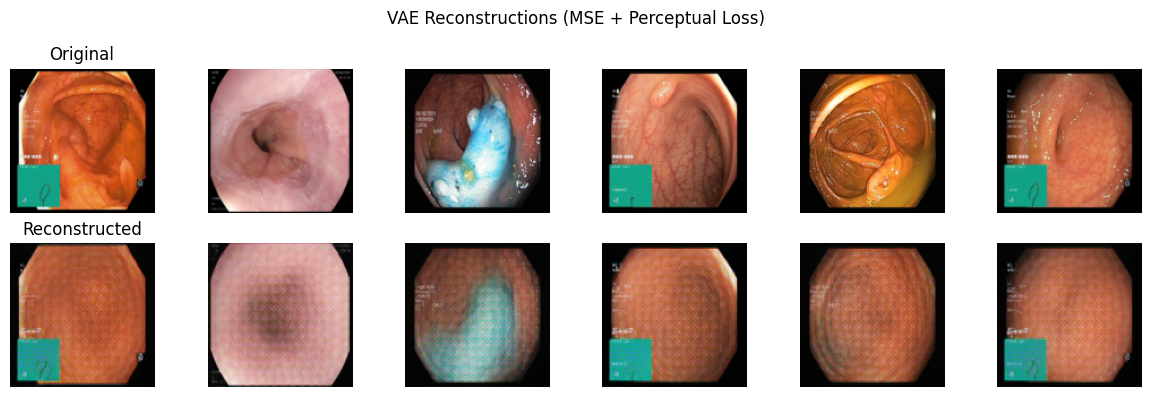

Saved reconstruction samples to ./plots/vae\reconstruction_samples.png


In [10]:
model.eval()
imgs, labels = next(iter(val_loader))
imgs = imgs.to(device)
with torch.no_grad():
    recon, mu, logvar = model(imgs)

n_show = 6
fig, axes = plt.subplots(2, n_show, figsize=(2 * n_show, 4))
for i in range(n_show):
    axes[0, i].imshow(imgs[i].cpu().permute(1, 2, 0).numpy()); axes[0, i].axis("off")
    axes[0, i].set_title("Original" if i == 0 else "")
    axes[1, i].imshow(recon[i].cpu().permute(1, 2, 0).numpy()); axes[1, i].axis("off")
    axes[1, i].set_title("Reconstructed" if i == 0 else "")

plt.suptitle("VAE Reconstructions (MSE + Perceptual Loss)")
plt.tight_layout()
plt.savefig(RECON_SAMPLES_PLOT_PATH, dpi=150)
plt.show()
print(f"Saved reconstruction samples to {RECON_SAMPLES_PLOT_PATH}")

## 10. Random generation — sampling directly from the prior

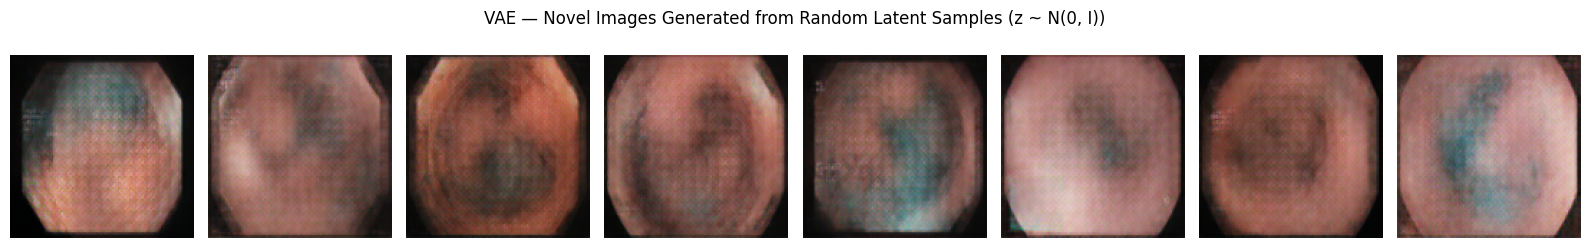

Saved random generation samples to ./plots/vae\random_generation_samples.png
Saved 200 synthetic images to ./synthetic_data/vae


In [11]:
model.eval()
n_gen = 8
with torch.no_grad():
    z_random = torch.randn(n_gen, LATENT_DIM).to(device)
    generated = model.decoder(z_random)

fig, axes = plt.subplots(1, n_gen, figsize=(2 * n_gen, 2.5))
for i in range(n_gen):
    axes[i].imshow(generated[i].cpu().permute(1, 2, 0).numpy())
    axes[i].axis("off")
plt.suptitle("VAE — Novel Images Generated from Random Latent Samples (z ~ N(0, I))")
plt.tight_layout()
plt.savefig(RANDOM_GEN_PLOT_PATH, dpi=150)
plt.show()
print(f"Saved random generation samples to {RANDOM_GEN_PLOT_PATH}")

with torch.no_grad():
    z_batch = torch.randn(200, LATENT_DIM).to(device)
    synthetic_batch = model.decoder(z_batch)
    for i, img in enumerate(synthetic_batch):
        save_image(img, os.path.join(SYNTH_DIR, f"synth_{i}.png"))
print(f"Saved 200 synthetic images to {SYNTH_DIR}")

## 11. Uniqueness experiment — latent interpolation between classes

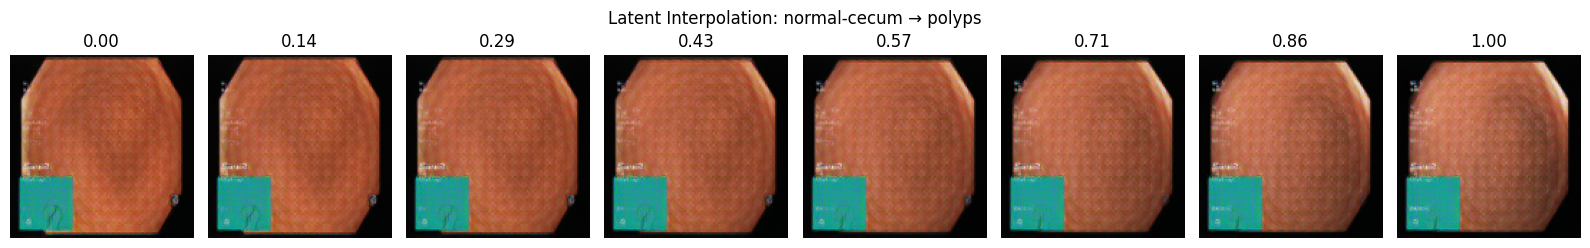

Saved interpolation grid to ./plots/vae\latent_interpolation.png


In [12]:
def get_one_image_per_class(dataset, class_names, target_classes):
    found = {}
    base = dataset.dataset if hasattr(dataset, "dataset") else dataset
    indices = dataset.indices if hasattr(dataset, "indices") else range(len(dataset))
    for idx in indices:
        img, label = base[idx] if hasattr(dataset, "dataset") else dataset[idx]
        cname = class_names[label]
        if cname in target_classes and cname not in found:
            found[cname] = img
        if len(found) == len(target_classes):
            break
    return found


class_a, class_b = "normal-cecum", "polyps"
examples = get_one_image_per_class(val_dataset, class_names, [class_a, class_b])

if class_a in examples and class_b in examples:
    img_a = examples[class_a].unsqueeze(0).to(device)
    img_b = examples[class_b].unsqueeze(0).to(device)

    model.eval()
    with torch.no_grad():
        mu_a, _ = model.encoder(img_a)
        mu_b, _ = model.encoder(img_b)

        steps = 8
        alphas = np.linspace(0, 1, steps)
        interpolated = [model.decoder(mu_a * (1 - a) + mu_b * a) for a in alphas]

    fig, axes = plt.subplots(1, steps, figsize=(2 * steps, 2.5))
    for i, img in enumerate(interpolated):
        axes[i].imshow(img.squeeze(0).cpu().permute(1, 2, 0).numpy())
        axes[i].axis("off")
        axes[i].set_title(f"{alphas[i]:.2f}")
    plt.suptitle(f"Latent Interpolation: {class_a} \u2192 {class_b}")
    plt.tight_layout()
    plt.savefig(INTERPOLATION_PLOT_PATH, dpi=150)
    plt.show()
    print(f"Saved interpolation grid to {INTERPOLATION_PLOT_PATH}")
else:
    print(f"Could not find examples for both classes: found {list(examples.keys())}")
    print("Available classes:", class_names)

## 12. Latent space visualization (t-SNE, colored by class)

Running t-SNE on 800 latent vectors...


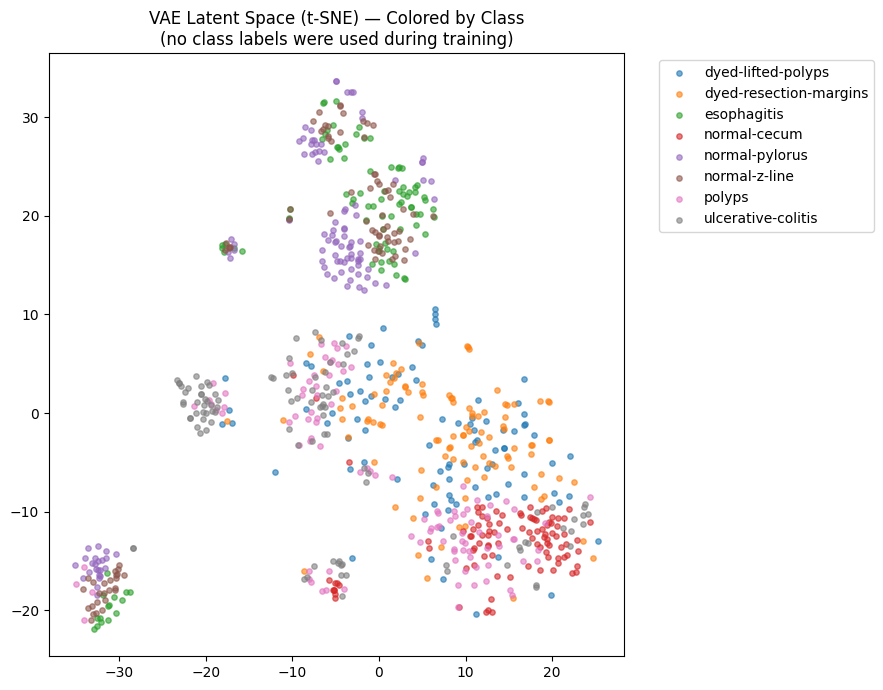

Saved t-SNE plot to ./plots/vae\latent_tsne_by_class.png


In [13]:
from sklearn.manifold import TSNE

model.eval()
all_mu, all_labels = [], []
with torch.no_grad():
    for imgs, labels in val_loader:
        imgs = imgs.to(device)
        mu, _ = model.encoder(imgs)
        all_mu.append(mu.cpu().numpy())
        all_labels.append(labels.numpy())

all_mu = np.concatenate(all_mu)
all_labels = np.concatenate(all_labels)

print(f"Running t-SNE on {len(all_mu)} latent vectors...")
tsne = TSNE(n_components=2, random_state=SEED, perplexity=30)
mu_2d = tsne.fit_transform(all_mu)

plt.figure(figsize=(9, 7))
cmap = plt.get_cmap("tab10")
for i, cname in enumerate(class_names):
    mask = all_labels == i
    plt.scatter(mu_2d[mask, 0], mu_2d[mask, 1], label=cname, alpha=0.6, s=15, color=cmap(i % 10))

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.title("VAE Latent Space (t-SNE) — Colored by Class\n(no class labels were used during training)")
plt.tight_layout()
plt.savefig(TSNE_PLOT_PATH, dpi=150)
plt.show()
print(f"Saved t-SNE plot to {TSNE_PLOT_PATH}")

## 13. Pretrained reference comparison (Stable Diffusion VAE)
Clearly labeled reference from a much larger, pretrained model — never presented as this project's own output.

d:\Savita\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
d:\Savita\.venv\lib\site-packages\huggingface_hub\utils\_validators.py:205: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


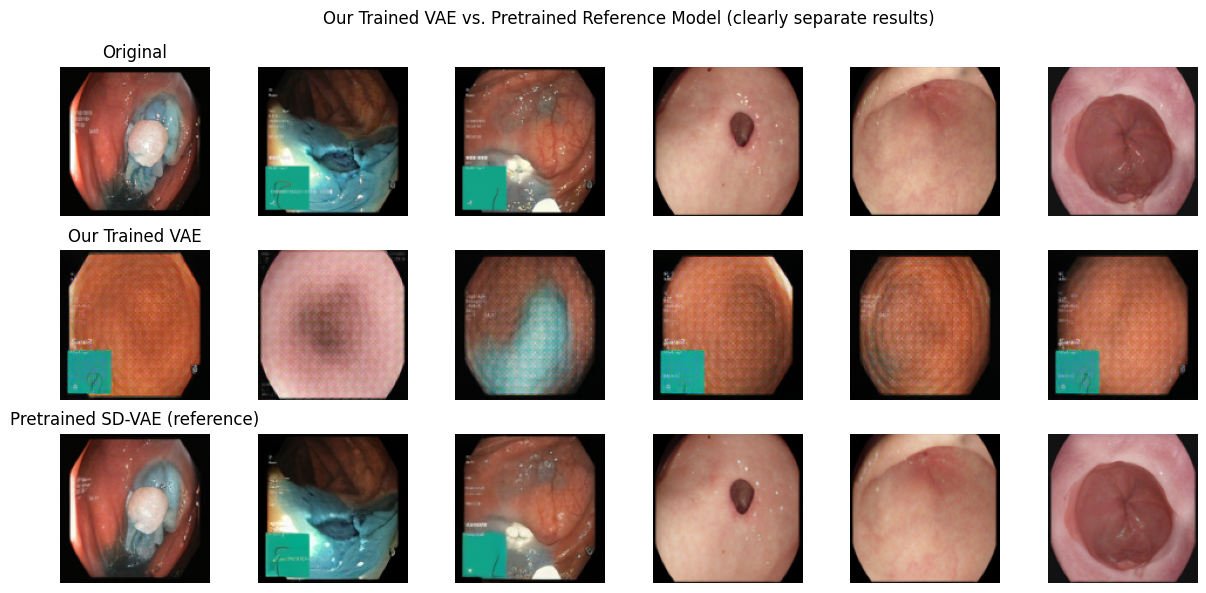

In [14]:
from diffusers import AutoencoderKL

pretrained_vae = AutoencoderKL.from_pretrained("stabilityai/sd-vae-ft-mse").to(device)
pretrained_vae.eval()
for p in pretrained_vae.parameters():
    p.requires_grad = False


def reconstruct_with_pretrained_vae(img_tensor):
    img_batch = img_tensor.unsqueeze(0).to(device)
    img_scaled = img_batch * 2.0 - 1.0
    with torch.no_grad():
        latent = pretrained_vae.encode(img_scaled).latent_dist.sample() * 0.18215
        recon = pretrained_vae.decode(latent / 0.18215).sample
    return ((recon.clamp(-1, 1) + 1.0) / 2.0).squeeze(0).cpu()


n_show = 6
fig, axes = plt.subplots(3, n_show, figsize=(2 * n_show, 6))
for i in range(n_show):
    pretrained_recon = reconstruct_with_pretrained_vae(imgs[i])
    axes[0, i].imshow(imgs[i].cpu().permute(1, 2, 0).numpy()); axes[0, i].axis("off")
    axes[0, i].set_title("Original" if i == 0 else "")
    axes[1, i].imshow(recon[i].cpu().permute(1, 2, 0).numpy()); axes[1, i].axis("off")
    axes[1, i].set_title("Our Trained VAE" if i == 0 else "")
    axes[2, i].imshow(pretrained_recon.permute(1, 2, 0).numpy()); axes[2, i].axis("off")
    axes[2, i].set_title("Pretrained SD-VAE (reference)" if i == 0 else "")

plt.suptitle("Our Trained VAE vs. Pretrained Reference Model (clearly separate results)")
plt.tight_layout()
plt.savefig(os.path.join(PLOTS_DIR, "pretrained_vae_comparison.png"), dpi=150)
plt.show()

In [15]:
# ---- Save pretrained reference model + its outputs locally ----
PRETRAINED_SAVE_DIR = os.path.join(MODEL_DIR, "pretrained_reference")
os.makedirs(PRETRAINED_SAVE_DIR, exist_ok=True)
pretrained_vae.save_pretrained(PRETRAINED_SAVE_DIR)
print(f"Saved pretrained reference model weights to {PRETRAINED_SAVE_DIR}")
# To reload later without internet:  pretrained_vae = AutoencoderKL.from_pretrained(PRETRAINED_SAVE_DIR).to(device)

PRETRAINED_OUTPUTS_DIR = os.path.join(MODEL_DIR, "pretrained_reference_outputs")
os.makedirs(PRETRAINED_OUTPUTS_DIR, exist_ok=True)
for i in range(n_show):
    pretrained_recon = reconstruct_with_pretrained_vae(imgs[i])
    save_image(pretrained_recon, os.path.join(PRETRAINED_OUTPUTS_DIR, f"pretrained_recon_{i}.png"))
print(f"Saved {n_show} pretrained reference reconstructions to {PRETRAINED_OUTPUTS_DIR}")

Saved pretrained reference model weights to ./models/vae\pretrained_reference
Saved 6 pretrained reference reconstructions to ./models/vae\pretrained_reference_outputs


## Output summary

| Artifact | Path |
|---|---|
| Trained model checkpoint | `models/vae/vae_best.pth` |
| Loss log (total, recon, perceptual, KL) | `metrics/vae/training_loss_log.csv` |
| Evaluation metrics (MSE, PSNR, SSIM) | `metrics/vae/evaluation_metrics.json` |
| Loss curve | `plots/vae/loss_curve.png` |
| Reconstruction samples | `plots/vae/reconstruction_samples.png` |
| Random generation samples | `plots/vae/random_generation_samples.png`, `synthetic_data/vae/` |
| Latent interpolation | `plots/vae/latent_interpolation.png` |
| Latent t-SNE by class | `plots/vae/latent_tsne_by_class.png` |
| Pretrained reference comparison | `plots/vae/pretrained_vae_comparison.png` |

**If training is still unstable:** lower `LEARNING_RATE` to `1e-4` and/or `BETA` to `0.01`, then set `FORCE_RETRAIN = True` and rerun. The printed max-KL check in section 6 will tell you immediately whether this run was stable.